# Protein-coding vs lncRNA genes across Annotrieve: which species have them annotated?

All Annotrieve annotations of **reference assemblies** (every database), summarised per species and lineage.

- **Reference assembly** = NCBI RefSeq category `reference genome`. Annotations on the GenBank twin of a reference
  assembly (GCA_X.v of a reference GCF_X.v: same accession number and version, same sequence) are included even when
  the flag is only set on the GCF.

**Definitions**
- **Protein-coding genes** = genes of the `coding` category with at least one `mRNA` transcript. Annotations without
  an mRNA level (CDS attached directly to the gene, mostly GenBank submitter files) fall back to the number of
  `coding` genes.
- **lncRNA genes** = genes of the `non_coding` category with at least one `lnc_RNA` or `lncRNA` transcript. The
  category alone is not used because `non_coding` also holds tRNA, snoRNA, miRNA, ...; the transcript type alone is
  not used because Ensembl GFFs also label retained-intron / processed transcripts of coding genes as `lnc_RNA`.
- **Species** = species-rank taxon of the annotation (strains and subspecies are collapsed into their species).
  A species "has" a gene class if at least one of its annotations has >= 1 gene of that class.


In [1]:
import io, json, os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests

API = "https://genome.crg.es/annotrieve/api/v0"
for d in ("work", "results", "figures"):
    os.makedirs(d, exist_ok=True)

LNC_TYPES = ["lnc_RNA", "lncRNA"]          # NCBI-style and alternative naming of the same transcript class
TYPES = ["mRNA"] + LNC_TYPES

# rows of the figure, top to bottom (taxid matched anywhere in the annotation's lineage)
LINEAGES = {"Mammalia": "40674", "Aves": "8782", "Actinopteri": "186623",                     # vertebrates
            "Insecta": "50557", "Arachnida": "6854", "Mollusca": "6447", "Cnidaria": "6073",   # invertebrates
            "Magnoliopsida": "3398",                                                         # flowering plants
            "Ascomycota": "4890", "Basidiomycota": "5204"}                                   # fungi
GROUP_BREAKS = ["Insecta", "Magnoliopsida", "Ascomycota"]    # first row of each new group (separator lines)
COLORS = {"protein-coding": "#2a78d6", "lncRNA": "#eb6834"}


def cached_json(path, fetch):
    """Fetch once and keep the response under work/ (delete the file to refresh from the live API)."""
    if not os.path.exists(path):
        with open(path, "w") as fh:
            json.dump(fetch(), fh)
    with open(path) as fh:
        return json.load(fh)

In [2]:
# 1. Retrieve all annotations of reference assemblies with their mRNA and lncRNA (lnc_RNA, lncRNA) transcript statistics
# reference flag: the annotation records do not carry it, /annotations/report does (assembly_refseq_category)
def fetch_report():
    r = requests.post(f"{API}/annotations/report", json={"selected_fields": "assembly_refseq_category"}, timeout=900)
    r.raise_for_status()
    return r.text


report = pd.read_csv(io.StringIO(cached_json("work/report_refseq_category.json", fetch_report)), sep="\t", dtype=str)
report["assembly"] = report.assembly_accession.str[4:]                    # accession.version without GCA_/GCF_
flagged = report.assembly_refseq_category == "reference genome"
reference = flagged | report.assembly.isin(set(report.loc[flagged, "assembly"]))   # + GCA twins of reference GCFs
reference_ids = set(report.annotation_id[reference])
print(f"reference assemblies: {flagged.sum()} annotations flagged + {(reference & ~flagged).sum()} on GCA twins "
      f"= {len(reference_ids)} of {len(report)}")

FIELDS = ",".join(["annotation_id", "organism_name", "taxid", "taxon_lineage", "assembly_accession",
                   "source_file_info.database", "features_statistics.gene_category_stats.coding.total_count"]
                  + [f"features_statistics.transcript_type_stats.{t}.{k}" for t in TYPES
                     for k in ("total_count", "associated_genes")])


def fetch_all(page=1000):
    out, offset = [], 0
    while True:
        r = requests.post(f"{API}/annotations", json={"limit": page, "offset": offset, "fields": FIELDS}, timeout=600)
        r.raise_for_status()
        d = r.json()
        out += d["results"]
        offset += page
        if offset >= d["total"]:
            assert len(out) == d["total"]
            return out


records = [r for r in cached_json("work/annotations_all.json", fetch_all) if r["annotation_id"] in reference_ids]
assert len(records) == len(reference_ids)


def tstats(rec, t):
    return ((rec.get("features_statistics") or {}).get("transcript_type_stats") or {}).get(t) or {}


ann = pd.DataFrame([{
    "annotation_id": r["annotation_id"], "organism_name": r["organism_name"], "taxid": str(r["taxid"]),
    "assembly_accession": r["assembly_accession"], "database": r["source_file_info"]["database"],
    **{f"tx_{t}": tstats(r, t).get("total_count", 0) for t in TYPES},
} for r in records])
ann["tx_lnc"] = ann[[f"tx_{t}" for t in LNC_TYPES]].sum(axis=1)
print(f"{len(ann)} annotations, {ann.organism_name.nunique()} organisms")
print(f"  with mRNA transcripts:   {(ann.tx_mRNA > 0).sum()}")
print(f"  with lncRNA transcripts: {(ann.tx_lnc > 0).sum()}  (lnc_RNA {(ann.tx_lnc_RNA > 0).sum()}, "
      f"lncRNA {(ann.tx_lncRNA > 0).sum()})")
ann.groupby("database")[["tx_mRNA", "tx_lnc"]].agg(lambda s: (s > 0).sum()).assign(
    annotations=ann.database.value_counts())

reference assemblies: 10637 annotations flagged + 58 on GCA twins = 10695 of 20153
10695 annotations, 7654 organisms
  with mRNA transcripts:   10484
  with lncRNA transcripts: 4395  (lnc_RNA 3830, lncRNA 565)


,tx_mRNA,tx_lnc,annotations
database,,,
CommunityRegistry,1365,0,1365
Ensembl,3314,2666,3314
GenBank,3424,156,3635
RefSeq,2381,1573,2381


In [3]:
# 2. Number of protein-coding and lncRNA genes per annotation (definitions at the top of the notebook)
def genes(rec, t, category):
    return (tstats(rec, t).get("associated_genes") or {}).get("gene_categories", {}).get(category, 0)


def coding_genes(rec):
    return (((rec.get("features_statistics") or {}).get("gene_category_stats") or {}).get("coding") or {}).get(
        "total_count", 0)


by_id = {r["annotation_id"]: r for r in records}
pc_mrna = np.array([genes(by_id[a], "mRNA", "coding") for a in ann.annotation_id])
pc_cds = np.array([coding_genes(by_id[a]) for a in ann.annotation_id])
ann["pc_from_cds_only"] = (ann.tx_mRNA == 0) & (pc_cds > 0)          # no mRNA level: CDS directly under the gene
ann["pc_genes"] = np.where(ann.pc_from_cds_only, pc_cds, pc_mrna)

lnc = pd.DataFrame([[genes(by_id[a], t, "non_coding") for t in LNC_TYPES] for a in ann.annotation_id],
                   columns=LNC_TYPES)
assert ((lnc > 0).sum(axis=1) < 2).all(), "an annotation uses both lnc_RNA and lncRNA: decide how to combine"
ann["lnc_genes"] = lnc.sum(axis=1)

ann["has_pc"], ann["has_lnc"] = ann.pc_genes > 0, ann.lnc_genes > 0
print(f"protein-coding genes from CDS-only annotations (no mRNA level): {ann.pc_from_cds_only.sum()} annotations")
print(f"lncRNA transcripts present but on no non-coding gene (not counted): {((ann.tx_lnc > 0) & ~ann.has_lnc).sum()}")
print(f"annotations with protein-coding genes: {ann.has_pc.sum()}  |  with lncRNA genes: {ann.has_lnc.sum()}  "
      f"(of {len(ann)})")
ann.groupby("database")[["pc_genes", "lnc_genes"]].median().rename(columns=lambda c: f"median {c}")

protein-coding genes from CDS-only annotations (no mRNA level): 211 annotations
lncRNA transcripts present but on no non-coding gene (not counted): 0
annotations with protein-coding genes: 10695  |  with lncRNA genes: 4395  (of 10695)


,median pc_genes,median lnc_genes
database,,
CommunityRegistry,24789.0,0.0
Ensembl,15915.0,1112.5
GenBank,13124.0,0.0
RefSeq,16399.0,1076.0


In [4]:
# 3. Group annotations and species into lineages
# species-rank taxon: the first species-rank taxid in the lineage (collapses strains / subspecies), else the taxid.
# Annotrieve only lists species-rank nodes that have strains / subspecies below them, which is all that is needed.
def fetch_rank(rank):
    taxa, offset = [], 0
    while True:
        r = requests.get(f"{API}/taxons", params={"rank": rank, "limit": 1000, "offset": offset}, timeout=120)
        r.raise_for_status()
        page = r.json()
        taxa += [str(t["taxid"]) for t in page["results"]]
        offset += 1000
        if offset >= page["total"]:
            return taxa


species_nodes = set(cached_json("work/taxa_species.json", lambda: fetch_rank("species")))
lineage_of = {v: k for k, v in LINEAGES.items()}
lineages = {r["annotation_id"]: [str(t) for t in r["taxon_lineage"]] for r in records}
ann["species_taxid"] = [next((t for t in lineages[a] if t in species_nodes), tx)
                        for a, tx in zip(ann.annotation_id, ann.taxid)]
ann["lineage"] = [next((lineage_of[t] for t in lineages[a] if t in lineage_of), None) for a in ann.annotation_id]
ann.to_csv("results/annotations_pc_lnc.tsv", sep="\t", index=False)

species = (ann[ann.lineage.notna()]
           .groupby(["lineage", "species_taxid"])
           .agg(organism_name=("organism_name", "first"), annotations=("annotation_id", "size"),
                has_pc=("has_pc", "any"), has_lnc=("has_lnc", "any"))
           .reset_index())
species.to_csv("results/species_pc_lnc.tsv", sep="\t", index=False)
print(f"{ann.lineage.notna().sum()} of {len(ann)} annotations and {len(species)} species fall in the "
      f"{len(LINEAGES)} lineages")

summary = species.groupby("lineage").agg(
    species=("species_taxid", "size"), annotations=("annotations", "sum"),
    species_with_pc=("has_pc", "sum"), species_with_lnc=("has_lnc", "sum")).reindex(list(LINEAGES))
summary["pct_pc"] = 100 * summary.species_with_pc / summary.species
summary["pct_lnc"] = 100 * summary.species_with_lnc / summary.species
summary.to_csv("results/lineage_species_pc_lnc.tsv", sep="\t", float_format="%.1f")
summary.round(1)

9071 of 10695 annotations and 6308 species fall in the 10 lineages


,species,annotations,species_with_pc,species_with_lnc,pct_pc,pct_lnc
lineage,,,,,,
Mammalia,678,1130,678,331,100.0,48.8
Aves,667,1194,667,257,100.0,38.5
Actinopteri,511,865,511,403,100.0,78.9
Insecta,1643,1868,1643,1193,100.0,72.6
Arachnida,77,117,77,48,100.0,62.3
Mollusca,183,239,183,177,100.0,96.7
Cnidaria,96,107,96,71,100.0,74.0
Magnoliopsida,665,812,665,374,100.0,56.2
Ascomycota,1306,1967,1306,94,100.0,7.2


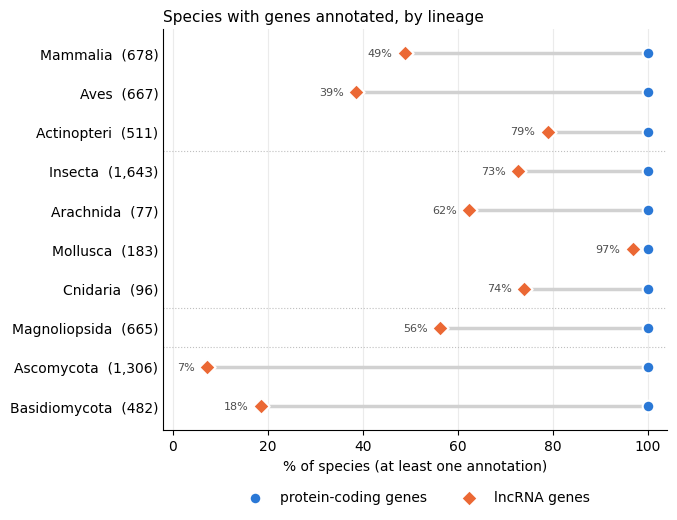

In [5]:
# 4. Per lineage: % of species with protein-coding genes and with lncRNA genes annotated
names = list(LINEAGES)
y = np.arange(len(names))[::-1]          # first lineage on top
fig, ax = plt.subplots(figsize=(6.5, 5.2))
pc, lnc = summary.pct_pc.values, summary.pct_lnc.values
ax.hlines(y, np.fmin(pc, lnc), np.fmax(pc, lnc), color="0.82", lw=2.5, zorder=1)
ax.scatter(pc, y, s=70, marker="o", color=COLORS["protein-coding"], edgecolor="white", lw=1.5, zorder=3,
           label="protein-coding genes")
ax.scatter(lnc, y, s=70, marker="D", color=COLORS["lncRNA"], edgecolor="white", lw=1.5, zorder=3,
           label="lncRNA genes")
for yy, v in zip(y, lnc):                # lncRNA value, left of its marker
    ax.annotate(f"{v:.0f}%", (v, yy), xytext=(-9, 0), textcoords="offset points", ha="right", va="center",
                fontsize=8, color="0.3")
for brk in GROUP_BREAKS:
    ax.axhline(y[names.index(brk)] + 0.5, color="0.75", lw=0.8, ls=":")
ax.set_yticks(y, [f"{n}  ({summary.loc[n, 'species']:,})" for n in names])
ax.set(xlim=(-2, 104), ylim=(-0.6, len(names) - 0.4), xlabel="% of species (at least one annotation)")
ax.set_title("Species with genes annotated, by lineage", fontsize=11, loc="left")
ax.spines[["top", "right"]].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.grid(axis="x", color="0.92", lw=0.8)
ax.set_axisbelow(True)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False)
fig.savefig("figures/species_pc_lnc_by_lineage.png", dpi=200, bbox_inches="tight")
fig.savefig("figures/species_pc_lnc_by_lineage.pdf", bbox_inches="tight")
plt.show()

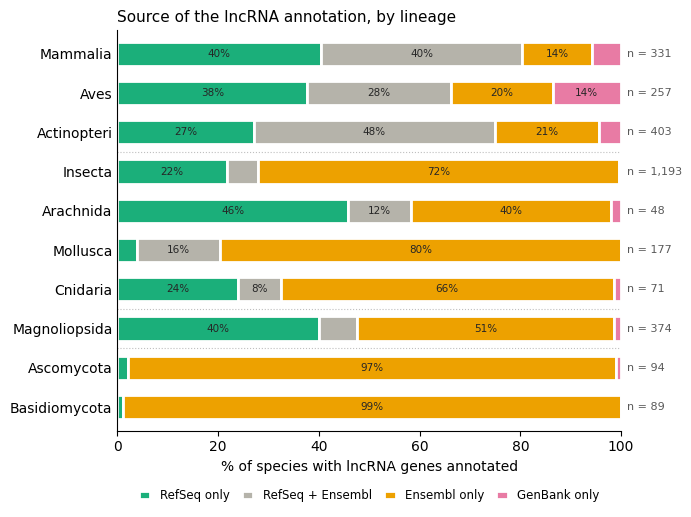

source,RefSeq only,RefSeq + Ensembl,Ensembl only,GenBank only,total
lineage,,,,,
Mammalia,134,132,46,19,331
Aves,97,73,52,35,257
Actinopteri,109,193,83,18,403
Insecta,260,74,853,6,1193
Arachnida,22,6,19,1,48
Mollusca,7,29,141,0,177
Cnidaria,17,6,47,1,71
Magnoliopsida,150,28,191,5,374
Ascomycota,2,0,91,1,94


In [6]:
# 5. Where does the lncRNA annotation of each species come from?
# source = databases whose annotations of the species carry >= 1 lncRNA gene. GenBank counts only when it is the sole
# source: next to RefSeq / Ensembl it is mostly a mirror of the same annotation. CommunityRegistry has no lncRNA.
SOURCES = {"RefSeq only": "#1baf7a", "RefSeq + Ensembl": "#b5b3aa", "Ensembl only": "#eda100",
           "GenBank only": "#e87ba4"}


def lnc_source(dbs):
    refseq, ensembl = "RefSeq" in dbs, "Ensembl" in dbs
    if refseq and ensembl:
        return "RefSeq + Ensembl"
    if refseq or ensembl:
        return "RefSeq only" if refseq else "Ensembl only"
    return "GenBank only" if dbs == {"GenBank"} else " + ".join(sorted(dbs))


lnc_species = (ann[ann.lineage.notna() & ann.has_lnc]
               .groupby(["lineage", "species_taxid"])
               .agg(organism_name=("organism_name", "first"),
                    lnc_databases=("database", lambda d: " + ".join(sorted(set(d)))),
                    source=("database", lambda d: lnc_source(set(d))))
               .reset_index())
assert lnc_species.source.isin(list(SOURCES)).all(), lnc_species.source.unique()
lnc_species.to_csv("results/species_lnc_source.tsv", sep="\t", index=False)

src_table = pd.crosstab(lnc_species.lineage, lnc_species.source).reindex(index=names, columns=list(SOURCES),
                                                                          fill_value=0)
pct = 100 * src_table.div(src_table.sum(axis=1), axis=0)
src_table.assign(total=src_table.sum(axis=1)).to_csv("results/lineage_lnc_source.tsv", sep="\t")

fig, ax = plt.subplots(figsize=(6.5, 5.2))
left = np.zeros(len(names))
for s, c in SOURCES.items():
    v = pct[s].values
    ax.barh(y, v, left=left, height=0.62, color=c, edgecolor="white", lw=2, label=s)
    for yy, l, w in zip(y, left, v):        # value labels on segments wide enough to hold them
        if w >= 8:
            ax.text(l + w / 2, yy, f"{w:.0f}%", ha="center", va="center", fontsize=7.5, color="0.15")
    left += v
for yy, n in zip(y, src_table.sum(axis=1).values):
    ax.annotate(f"n = {n:,}", (100, yy), xytext=(4, 0), textcoords="offset points", va="center", fontsize=8,
                color="0.35", annotation_clip=False)
for brk in GROUP_BREAKS:
    ax.axhline(y[names.index(brk)] + 0.5, color="0.75", lw=0.8, ls=":")
ax.set_yticks(y, names)
ax.set(xlim=(0, 100), ylim=(-0.6, len(names) - 0.4), xlabel="% of species with lncRNA genes annotated")
ax.set_title("Source of the lncRNA annotation, by lineage", fontsize=11, loc="left")
ax.spines[["top", "right"]].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=4, frameon=False, fontsize=8.5,
          handlelength=1, columnspacing=1)
fig.savefig("figures/species_lnc_source_by_lineage.png", dpi=200, bbox_inches="tight")
fig.savefig("figures/species_lnc_source_by_lineage.pdf", bbox_inches="tight")
plt.show()
src_table.assign(total=src_table.sum(axis=1))

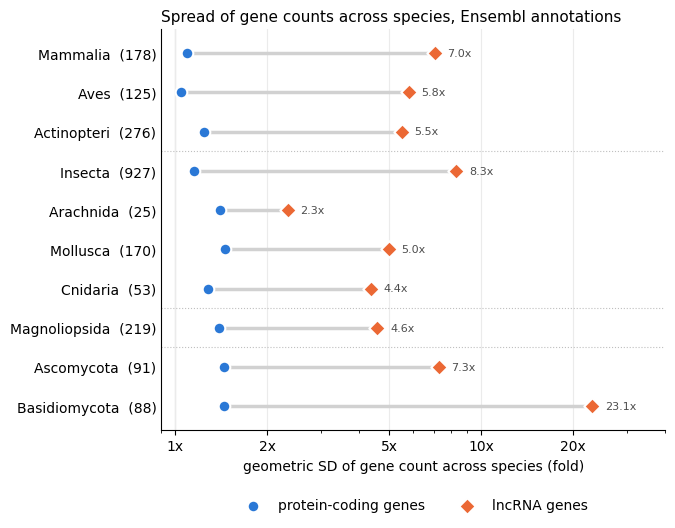

,species,gsd_pc,gsd_lnc,median_pc,median_lnc
lineage,,,,,
Mammalia,178,1.09,7.04,19405.00,1014.0
Aves,125,1.05,5.80,15404.00,918.0
Actinopteri,276,1.24,5.52,22908.50,1864.5
Insecta,927,1.15,8.31,12750.00,1529.0
Arachnida,25,1.40,2.34,15106.00,3138.0
Mollusca,170,1.45,4.99,21558.75,7070.5
Cnidaria,53,1.28,4.38,27298.00,3334.0
Magnoliopsida,219,1.39,4.58,30792.00,4151.0
Ascomycota,91,1.44,7.27,10310.00,2.0


In [7]:
# 6. Spread of protein-coding and lncRNA gene counts across species, Ensembl annotations only
# One pipeline, so the spread is not inflated by mixing RefSeq and Ensembl. Species = every species with >= 1 Ensembl
# annotation carrying lncRNA genes (lncRNA source "Ensembl only" or "RefSeq + Ensembl"); per species the median over
# those Ensembl annotations -> one protein-coding and one lncRNA count per species, from the same annotations.
# Spread across species: geometric SD = 10 ** SD(log10 count), the typical fold deviation from the geometric mean.
MIN_N = 10   # species needed for a value; fewer -> not shown

ens = ann[ann.lineage.notna() & ann.has_lnc & (ann.database == "Ensembl")]
per_species = ens.groupby(["lineage", "species_taxid"])[["pc_genes", "lnc_genes"]].median()


def gsd(x):
    return 10 ** np.log10(x).std() if len(x) >= MIN_N else np.nan


spread = (per_species.groupby("lineage")
          .agg(species=("pc_genes", "size"), gsd_pc=("pc_genes", gsd), gsd_lnc=("lnc_genes", gsd),
               median_pc=("pc_genes", "median"), median_lnc=("lnc_genes", "median"))
          .reindex(names))
spread["species"] = spread.species.fillna(0).astype(int)
spread.to_csv("results/lineage_ensembl_gene_count_gsd.tsv", sep="\t", float_format="%.3g")

fig, ax = plt.subplots(figsize=(6.5, 5.2))
pc, lnc = spread.gsd_pc.values, spread.gsd_lnc.values
ax.hlines(y, np.fmin(pc, lnc), np.fmax(pc, lnc), color="0.82", lw=2.5, zorder=1)
ax.scatter(pc, y, s=70, marker="o", color=COLORS["protein-coding"], edgecolor="white", lw=1.5, zorder=3,
           label="protein-coding genes")
ax.scatter(lnc, y, s=70, marker="D", color=COLORS["lncRNA"], edgecolor="white", lw=1.5, zorder=3,
           label="lncRNA genes")
for yy, v in zip(y, lnc):                # lncRNA value, right of its marker
    if np.isfinite(v):
        ax.annotate(f"{v:.1f}x", (v, yy), xytext=(9, 0), textcoords="offset points", va="center", fontsize=8,
                    color="0.3")
for brk in GROUP_BREAKS:
    ax.axhline(y[names.index(brk)] + 0.5, color="0.75", lw=0.8, ls=":")
ax.axvline(1, color="0.6", lw=0.8, zorder=0)
ax.set_yticks(y, [f"{n}  ({k:,})" if np.isfinite(spread.loc[n, "gsd_lnc"]) else f"{n}  ({k}, < {MIN_N})"
                  for n, k in zip(names, spread.species)])
ax.set(xscale="log", xlim=(0.9, 40), ylim=(-0.6, len(names) - 0.4),
       xlabel="geometric SD of gene count across species (fold)")
ax.set_xticks([1, 2, 5, 10, 20])
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}x"))
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set_title("Spread of gene counts across species, Ensembl annotations", fontsize=11, loc="left")
ax.spines[["top", "right"]].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.grid(axis="x", color="0.92", lw=0.8)
ax.set_axisbelow(True)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2, frameon=False)
fig.savefig("figures/lineage_ensembl_gene_count_gsd.png", dpi=200, bbox_inches="tight")
fig.savefig("figures/lineage_ensembl_gene_count_gsd.pdf", bbox_inches="tight")
plt.show()
spread.round(2)

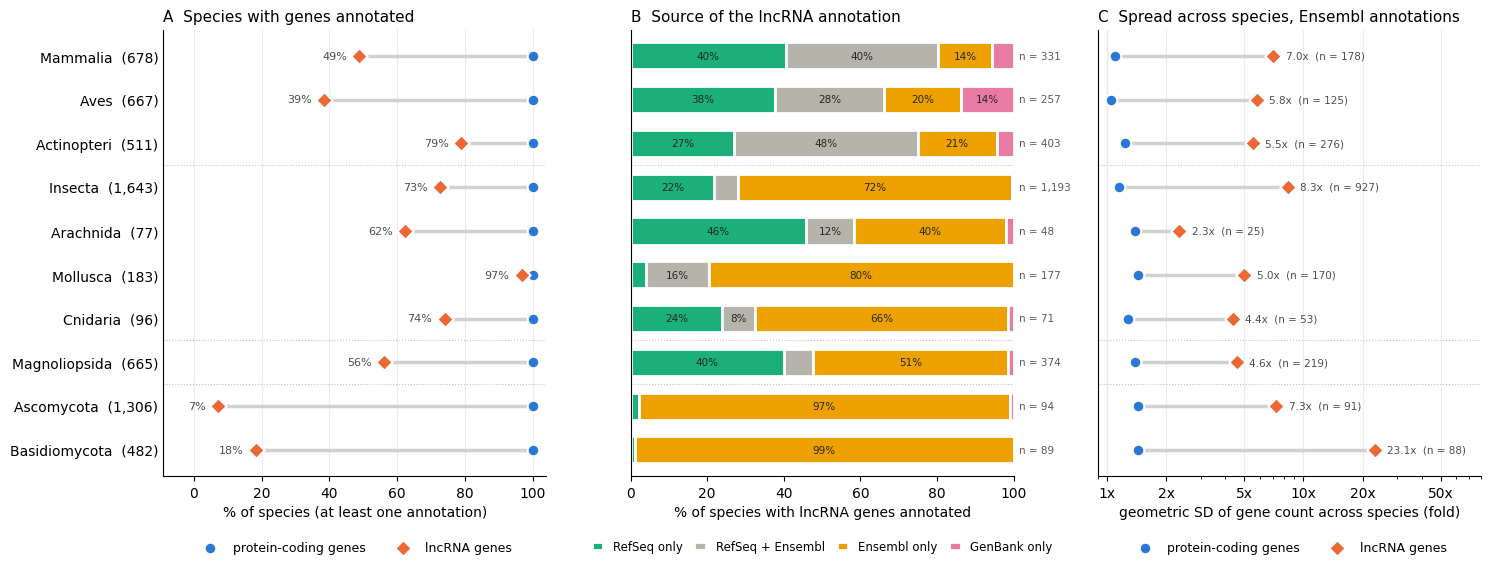

In [8]:
# 7. Combined figure: A presence (step 4) | B source of the lncRNA annotation (step 5) | C Ensembl spread (step 6)
fig, axes = plt.subplots(1, 3, figsize=(17, 5.8), sharey=True, gridspec_kw={"wspace": 0.22})


def dumbbell(ax, a, b):
    ax.hlines(y, np.fmin(a, b), np.fmax(a, b), color="0.82", lw=2.5, zorder=1)
    ax.scatter(a, y, s=70, marker="o", color=COLORS["protein-coding"], edgecolor="white", lw=1.5, zorder=3,
               label="protein-coding genes")
    ax.scatter(b, y, s=70, marker="D", color=COLORS["lncRNA"], edgecolor="white", lw=1.5, zorder=3,
               label="lncRNA genes")


# A: % of species with genes annotated
ax = axes[0]
dumbbell(ax, summary.pct_pc.values, summary.pct_lnc.values)
for yy, v in zip(y, summary.pct_lnc.values):
    ax.annotate(f"{v:.0f}%", (v, yy), xytext=(-9, 0), textcoords="offset points", ha="right", va="center",
                fontsize=8, color="0.3")
ax.set(xlim=(-9, 104), xlabel="% of species (at least one annotation)")
ax.set_title("A  Species with genes annotated", fontsize=11, loc="left")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False, fontsize=9)

# B: source of the lncRNA annotation
ax = axes[1]
left = np.zeros(len(names))
for s, c in SOURCES.items():
    v = pct[s].values
    ax.barh(y, v, left=left, height=0.62, color=c, edgecolor="white", lw=2, label=s)
    for yy, l, w in zip(y, left, v):
        if w >= 8:
            ax.text(l + w / 2, yy, f"{w:.0f}%", ha="center", va="center", fontsize=7.5, color="0.15")
    left += v
for yy, n in zip(y, src_table.sum(axis=1).values):
    ax.annotate(f"n = {n:,}", (100, yy), xytext=(4, 0), textcoords="offset points", va="center", fontsize=7.5,
                color="0.35", annotation_clip=False)
ax.set(xlim=(0, 100), xlabel="% of species with lncRNA genes annotated")
ax.set_title("B  Source of the lncRNA annotation", fontsize=11, loc="left")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=4, frameon=False, fontsize=8.5,
          handlelength=1, columnspacing=1)

# C: spread across species, Ensembl annotations
ax = axes[2]
dumbbell(ax, spread.gsd_pc.values, spread.gsd_lnc.values)
for yy, v, k in zip(y, spread.gsd_lnc.values, spread.species.values):
    ax.annotate(f"{v:.1f}x  (n = {k:,})" if np.isfinite(v) else f"n = {k} (< {MIN_N})", (v if np.isfinite(v) else 1, yy),
                xytext=(9, 0), textcoords="offset points", va="center", fontsize=7.5, color="0.3")
ax.axvline(1, color="0.6", lw=0.8, zorder=0)
ax.set(xscale="log", xlim=(0.9, 80), xlabel="geometric SD of gene count across species (fold)")
ax.set_xticks([1, 2, 5, 10, 20, 50])
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}x"))
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set_title("C  Spread across species, Ensembl annotations", fontsize=11, loc="left")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False, fontsize=9)

for ax in axes:
    for brk in GROUP_BREAKS:
        ax.axhline(y[names.index(brk)] + 0.5, color="0.75", lw=0.8, ls=":")
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(axis="y", length=0)
    ax.grid(axis="x", color="0.92", lw=0.8)
    ax.set_axisbelow(True)
axes[1].grid(False)
axes[0].set_yticks(y, [f"{n}  ({summary.loc[n, 'species']:,})" for n in names])
axes[0].set_ylim(-0.6, len(names) - 0.4)
fig.savefig("figures/lnc_vs_pcg_combined.png", dpi=200, bbox_inches="tight")
fig.savefig("figures/lnc_vs_pcg_combined.pdf", bbox_inches="tight")
plt.show()